# 3.0 · EDA y preprocesamiento

Usa las funciones de `mibici_demand/plots.py` y `mibici_demand/features.py`.
Requiere haber corrido `make data` (genera `data/interim/trips_clean.parquet`).

In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from mibici_demand import plots
from mibici_demand.config import CLEAN_TRIPS_FILE, FEATURE_PARAMS
from mibici_demand.dataset import load_stations

trips = pd.read_parquet(CLEAN_TRIPS_FILE)
stations = load_stations()
trips.shape

2026-10-25 17:30:04.284 | INFO     | mibici_demand.config:<module>:16 - PROJ_ROOT path is: C:\Users\Sam\Downloads\mibici-demand-main\mibici-demand-main


2026-10-25 17:30:06.762 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo nomenclatura_2026_09.csv
2026-10-25 17:30:06.769 | INFO     | mibici_demand.dataset:load_stations:218 - Catálogo de estaciones: nomenclatura_2026_09.csv (484 estaciones)


(37643853, 11)

## 1. Tendencia temporal

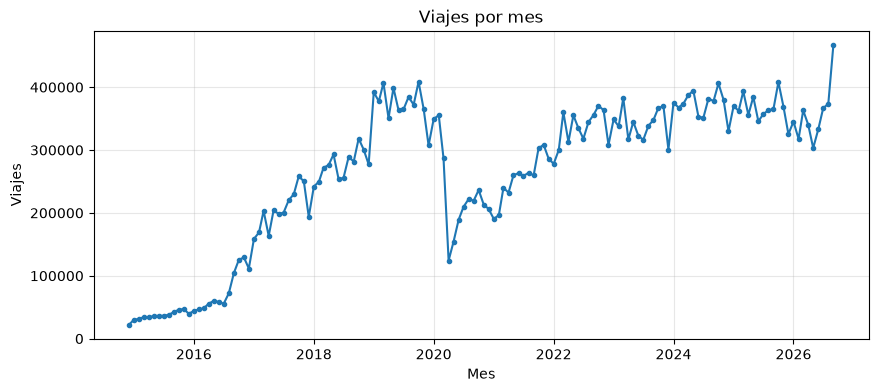

In [2]:
plots.plot_monthly_trend(trips);

## 2. Patrones por hora y día
¿Hay picos de entrada/salida al trabajo entre semana?

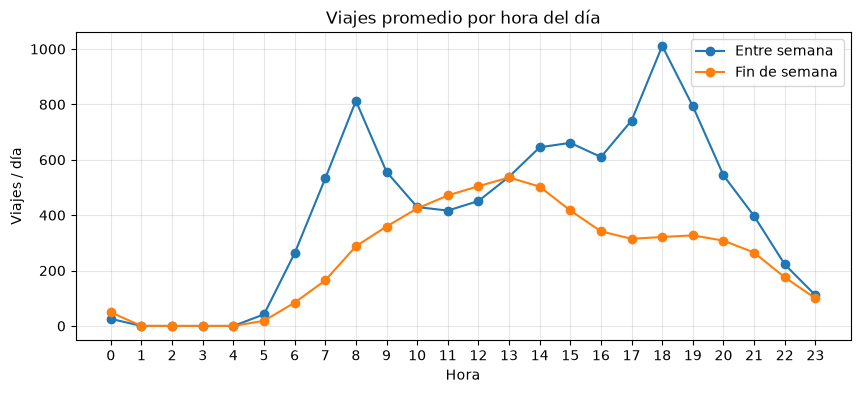

In [3]:
plots.plot_demand_by_hour(trips);

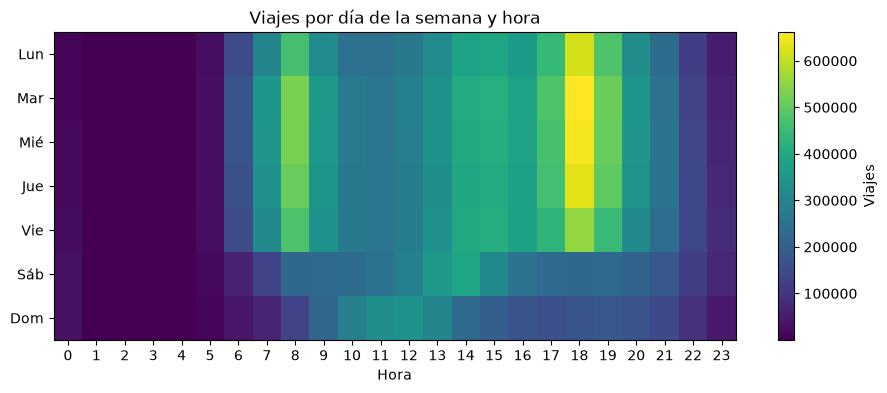

In [4]:
plots.plot_heatmap_day_hour(trips);

## 3. Duración, estaciones y usuarios

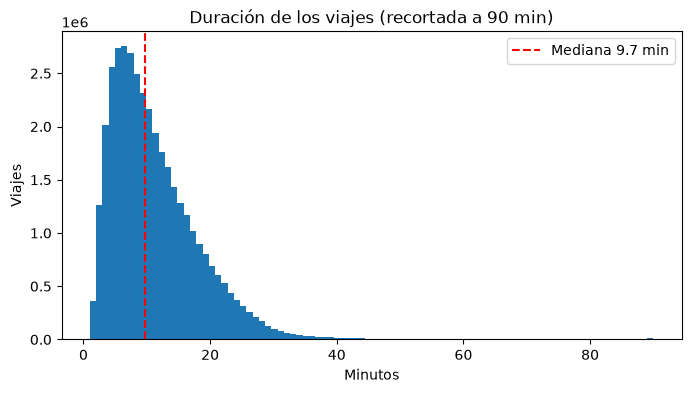

In [5]:
plots.plot_duration_distribution(trips);

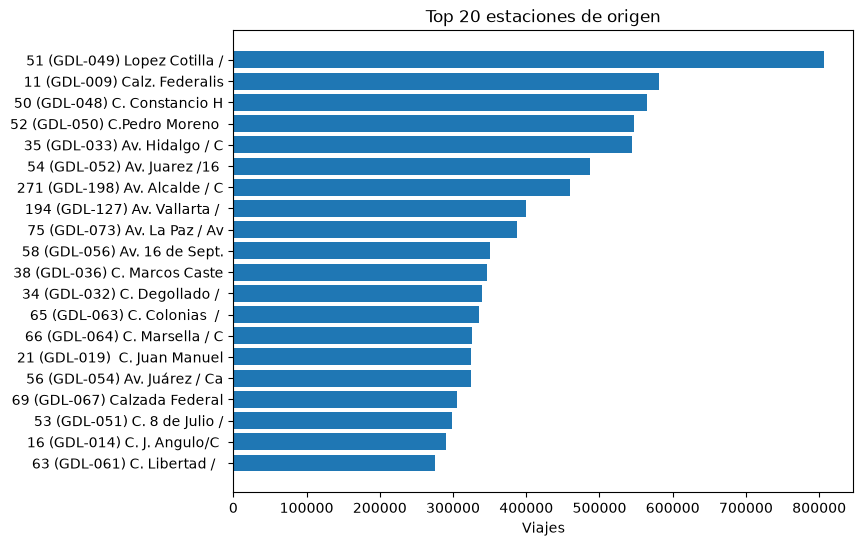

In [6]:
plots.plot_top_stations(trips, stations);

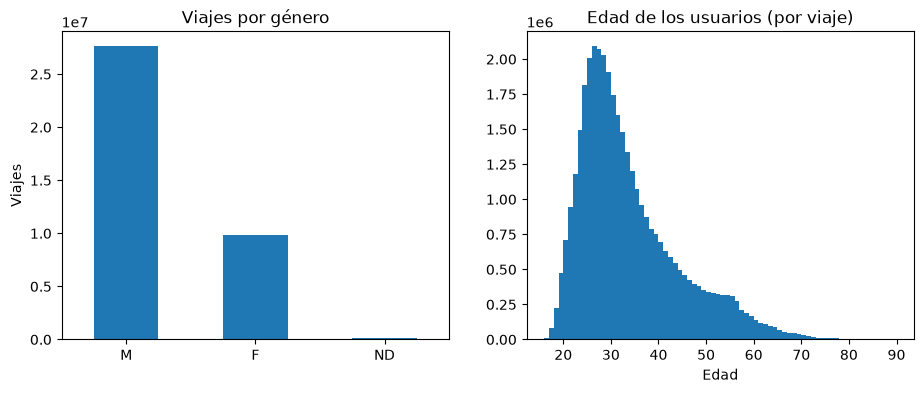

In [7]:
plots.plot_demographics(trips);

## 4. Variable objetivo: salidas por estación y hora
Se agregan los viajes y se añaden variables de calendario, rezagos y ubicación.

In [8]:
from mibici_demand.features import build_features, temporal_split, transform_split

features = build_features(trips[["start_time", "origin_id"]], stations)
features.head()

,station_id,timestamp,departures,hour,dayofweek,month,is_weekend,is_holiday,hour_sin,hour_cos,dow_sin,dow_cos,lag_1,lag_24,lag_168,rolling_mean_24,latitude,longitude
0,2,2014-12-08 18:00:00,0,18,0,12,0,0,-1.000000,-1.836970e-16,0.0,1.0,0.0,0.0,1.0,0.250000,20.666378,-103.34882
1,2,2014-12-08 19:00:00,1,19,0,12,0,0,-0.965926,2.588190e-01,0.0,1.0,0.0,1.0,0.0,0.250000,20.666378,-103.34882
2,2,2014-12-08 20:00:00,1,20,0,12,0,0,-0.866025,5.000000e-01,0.0,1.0,1.0,0.0,0.0,0.250000,20.666378,-103.34882
3,2,2014-12-08 21:00:00,0,21,0,12,0,0,-0.707107,7.071068e-01,0.0,1.0,1.0,0.0,0.0,0.291667,20.666378,-103.34882
4,2,2014-12-08 22:00:00,0,22,0,12,0,0,-0.500000,8.660254e-01,0.0,1.0,0.0,0.0,1.0,0.291667,20.666378,-103.34882


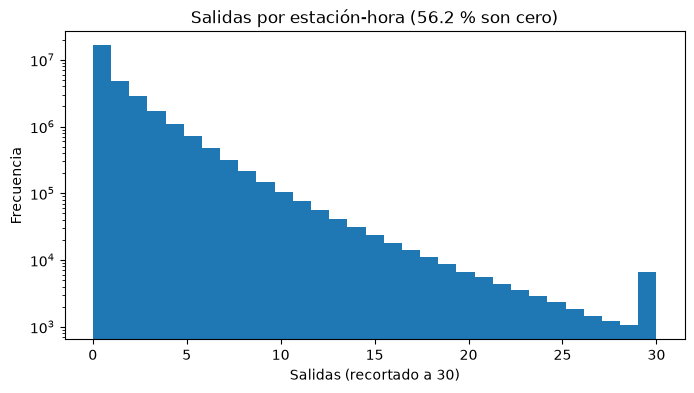

In [9]:
plots.plot_demand_distribution(features);

In [10]:
features[["departures", "lag_1", "lag_24", "lag_168", "rolling_mean_24"]].corr()["departures"]

departures         1.000000
lag_1              0.665487
lag_24             0.672864
lag_168            0.737073
rolling_mean_24    0.535803
Name: departures, dtype: float64

## 5. Preprocesamiento
- Split **temporal** (último 20 % como test) para no usar el futuro.
- `StandardScaler` en rezagos y coordenadas, one-hot del mes, codificación cíclica de
  hora/día, y `TargetEncoder` para la estación (one-hot de ~370 estaciones no cabe en memoria).
- El preprocesador se ajusta **solo con train**.

In [11]:
train, test = temporal_split(features, FEATURE_PARAMS["test_fraction"])
train_t, test_t, preprocessor = transform_split(train, test)
print(train_t.shape, test_t.shape)
train_t.describe().T.round(2)

C:\Users\Sam\Downloads\mibici-demand-main\mibici-demand-main\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


(21120492, 28) (8093859, 28)


,count,mean,min,25%,50%,75%,max,std
station_id,21120492.0,145.39077,2.0,66.0,140.0,218.0,388.0,90.622231
timestamp,21120492,2020-05-23 06:19:44.417239040,2014-12-08 00:00:00,2018-05-17 06:00:00,2020-07-21 22:00:00,2022-07-21 15:00:00,2024-05-20 23:00:00,NaN
x_lag_1,21120492.0,-0.0,-0.540667,-0.540667,-0.540667,0.296108,37.532606,1.0
x_lag_24,21120492.0,0.0,-0.54056,-0.54056,-0.54056,0.296408,37.54149,1.0
x_lag_168,21120492.0,-0.0,-0.539947,-0.539947,-0.539947,0.297958,37.584717,1.0
x_rolling_mean_24,21120492.0,-0.0,-0.94822,-0.672979,-0.275407,0.336241,11.621152,1.0
x_latitude,21120492.0,-0.0,-1.942349,-0.565559,-0.191121,0.324964,2.614562,1.0
x_longitude,21120492.0,-0.0,-2.39596,-0.759443,-0.044621,0.619932,2.516592,1.0
x_month_1,21120492.0,0.08942,0.0,0.0,0.0,0.0,1.0,0.285349
x_month_2,21120492.0,0.081664,0.0,0.0,0.0,0.0,1.0,0.273852


## 6. Reducción de dimensionalidad: PCA de perfiles de estación
Cada estación se describe por su demanda media en las 168 horas de la semana.

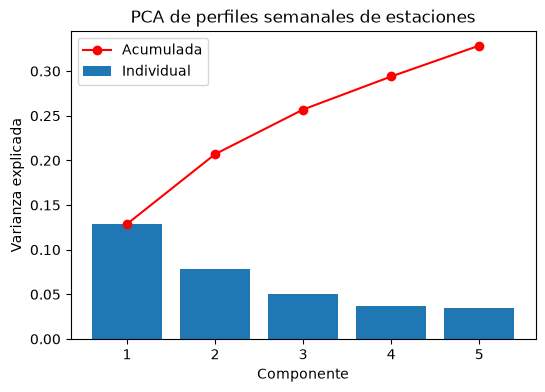

In [12]:
from mibici_demand.features import station_profiles_pca

scores, pca, profiles = station_profiles_pca(features, FEATURE_PARAMS["pca_components"])
plots.plot_pca_variance(pca);

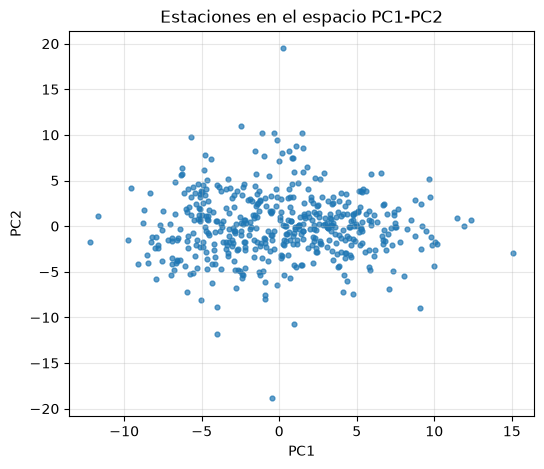

In [13]:
plots.plot_pca_stations(scores);

## Conclusiones del EDA (versión v2: dic-2014 a sep-2026, 37,643,853 viajes limpios, 483 estaciones)

1. **Patrón de traslado al trabajo.** Entre semana hay dos picos claros: 8 h (~810 viajes en promedio
   por día) y 18 h (~1,000). En fin de semana la demanda es más plana, con un máximo cerca de las 13 h.
   La hora, el día y el indicador de fin de semana son variables clave.
2. **Horario de operación.** Casi no hay viajes de 1 a 4 h; esas horas forman parte del 56.2 % de
   registros estación-hora con demanda cero.
3. **Tendencia de largo plazo.** La demanda creció de ~30 mil viajes al mes (2015) a ~400 mil (2019),
   cayó a ~120 mil en 2020 (pandemia) y se recuperó desde 2022, con el máximo del periodo en sep-2026.
   2020 es un periodo atípico que el modelo de la Fase 2 debe tratar (excluirlo o marcarlo).
4. **Demanda concentrada.** La estación 51 (López Cotilla) suma ~800 mil salidas, ~38 % más que la
   segunda (~580 mil). Pocas estaciones concentran mucha demanda: prioridad para la redistribución.
5. **Viajes cortos.** La mediana de duración es de 9.7 min; casi todos los viajes duran menos de 40 min.
6. **Usuarios.** Alrededor de 73 % de los viajes son de hombres; la edad más frecuente está entre 25 y 35 años.
7. **Historia reciente como predictor.** La demanda de la misma hora una semana antes (`lag_168`) es la
   variable más correlacionada (0.74), por encima de un día antes (0.67) y una hora antes (0.67).
8. **PCA de perfiles de estación.** Los 5 primeros componentes explican 33 % de la varianza
   (PC1: 12.9 %). En el plano PC1-PC2 no hay grupos separados con claridad; los componentes se
   usarán como variables adicionales en la Fase 2.
9. **Preprocesamiento.** Split temporal: 21,120,492 filas de entrenamiento (hasta 2024-05-20) y
   8,093,859 de prueba (desde 2024-05-21). Las variables numéricas quedan estandarizadas con
   estadísticas solo de entrenamiento.